# Bloque 1 Importar librerias

In [58]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
np.random.seed(42)
print("Listo")

Listo


# Bloque 2 Datos de alimentos

In [59]:
alimentos = pd.DataFrame({
    "alimento": ["Pollo", "Arroz", "Huevo", "Frijoles", "Tortilla", "Leche", "Platano", "Avena"],
    "costo": [45, 18, 8, 20, 4, 15, 10, 12],
    "calorías": [250, 220, 70, 180, 60, 120, 100, 150],
    "proteína": [35, 5, 6, 10, 2, 8, 1, 5],
    "carbohidratos": [0, 45, 1, 30, 12, 12, 27, 27],
    "grasa": [8, 2, 5, 2, 1, 5, 0, 3]
})
columnas_totales = ["costo", "calorías", "proteína", "carbohidratos", "grasa"]
print(alimentos.to_string(index=False))

alimento  costo  calorías  proteína  carbohidratos  grasa
   Pollo     45       250        35              0      8
   Arroz     18       220         5             45      2
   Huevo      8        70         6              1      5
Frijoles     20       180        10             30      2
Tortilla      4        60         2             12      1
   Leche     15       120         8             12      5
 Platano     10       100         1             27      0
   Avena     12       150         5             27      3


# Bloque 3 Parametros del problema

In [60]:
calorias_minimas = 1800
calorias_maximas = 2200
proteina_minima = 90
carbohidratos_minimos = 200
grasa_maxima = 70
max_porciones = 5
numero_genes = len(alimentos)

print("Calorias: ", calorias_minimas, " a ", calorias_maximas, "kcal")
print("Proteina minima: ", proteina_minima, "g")
print("Carbohidratos minimos: ", carbohidratos_minimos, "g")
print("Grasa maxima: ", grasa_maxima, "g")
print("Porciones por alimenmto: 0 a", max_porciones)

Calorias:  1800  a  2200 kcal
Proteina minima:  90 g
Carbohidratos minimos:  200 g
Grasa maxima:  70 g
Porciones por alimenmto: 0 a 5


# Bloque 4 Representacion de un individuo

In [61]:
individuo_ejemplo = np.array([2, 3, 1, 2, 4, 1, 2, 1])
print("Individuo:", individuo_ejemplo)
for columna in columnas_totales:
    aportaciones = individuo_ejemplo * alimentos[columna].to_numpy()
    print(columna, "total: ", aportaciones.sum())

Individuo: [2 3 1 2 4 1 2 1]
costo total:  255
calorías total:  2300
proteína total:  134
carbohidratos total:  337
grasa total:  43


# Bloque 5 Creacion de la poblacion inicial

In [62]:
POBLACION = 100
def crear_poblacion(tamano_poblacion, numero_genes, max_porciones):
    return np.random.randint(0, max_porciones + 1, size=(tamano_poblacion, numero_genes))

poblacion_ejemplo = crear_poblacion(POBLACION, numero_genes, max_porciones)
print("Poblacion de ejemplo: ", poblacion_ejemplo.shape)
print("Primeros 5 individuos:\n", poblacion_ejemplo[:5])

Poblacion de ejemplo:  (100, 8)
Primeros 5 individuos:
 [[3 4 2 4 4 1 2 2]
 [2 4 3 2 5 4 1 3]
 [5 5 1 3 4 0 3 1]
 [5 4 3 0 0 2 2 1]
 [3 3 5 5 5 2 3 3]]


# Bloque 6 Evaluacion nutricional

In [63]:
def evaluar_individuo(individuo):
    totales = {}
    for columna in columnas_totales:
        aportaciones = individuo * alimentos[columna].to_numpy()
        totales[columna] = aportaciones.sum()
    return totales

print("Evaluacion del ejemplo:")
print(pd.Series(evaluar_individuo(individuo_ejemplo)).to_string())

Evaluacion del ejemplo:
costo             255
calorías         2300
proteína          134
carbohidratos     337
grasa              43


# Bloque 7 Funcion Fitness

In [64]:
factor_calorias_bajas = 5
factor_calorias_altas = 5
factor_proteina = 20
factor_carbohidratos = 10
factor_grasa = 20

def calcular_fitness(individuo):
    totales = evaluar_individuo(individuo)
    penalizacion_calorias_bajas = max(0, calorias_minimas - totales["calorías"])
    penalizacion_calorias_altas = max(0, totales["calorías"] - calorias_maximas)
    penalizacion_proteina = max(0, proteina_minima - totales["proteína"])
    penalizacion_carbohidratos = max(0, carbohidratos_minimos - totales["carbohidratos"])
    penalizacion_grasa = max(0, totales["grasa"] - grasa_maxima)

    fitness = totales["costo"]
    fitness += factor_calorias_bajas * penalizacion_calorias_bajas
    fitness += factor_calorias_altas * penalizacion_calorias_altas
    fitness += factor_proteina * penalizacion_proteina
    fitness += factor_carbohidratos * penalizacion_carbohidratos
    fitness += factor_grasa * penalizacion_grasa
    return fitness

print("Fitness del ejemplo:", calcular_fitness(individuo_ejemplo))

Fitness del ejemplo: 755


# Bloque 8 Evaluar toda la poblacion

In [65]:
def evaluar_poblacion(poblacion):
    valores_fitness = []
    for individuo in poblacion:
        valores_fitness.append(calcular_fitness(individuo))
    return np.array(valores_fitness)

fitness_ejemplo = evaluar_poblacion(poblacion_ejemplo)
indice_mejor_ejemplo = np.argmin(fitness_ejemplo)
print(pd.DataFrame({"individuo": np.arange(1, 101), "fitness": fitness_ejemplo}).to_string(index=False))
print("Mejor fitness inicial del ejemplo:", fitness_ejemplo[indice_mejor_ejemplo])
print("Mejor individuo inicial del ejemplo:", poblacion_ejemplo[indice_mejor_ejemplo])

 individuo  fitness
         1     6128
         2     5892
         3     7691
         4     4153
         5     9575
         6      410
         7      416
         8     5745
         9     5211
        10     2330
        11     8894
        12     6810
        13     2253
        14     1660
        15     1471
        16     2292
        17     1784
        18     2098
        19     5599
        20     7490
        21     4741
        22     6730
        23      315
        24      289
        25     9026
        26     1385
        27      809
        28     1256
        29     7581
        30     5807
        31     5451
        32     2034
        33      257
        34      246
        35      204
        36     3173
        37     1162
        38     5199
        39     6035
        40     2515
        41     2548
        42    14675
        43     3733
        44     3727
        45    12744
        46     2190
        47      206
        48     3530
        49     3510


# Bloque 9 Seleccion por torneo binario

In [66]:
def seleccion_torneo(poblacion, fitness):
    indices = np.random.choice(len(poblacion), size=50, replace=False)
    primero = indices[0]
    segundo = indices[1]
    if fitness[primero] <= fitness[segundo]:
        ganador = primero
    else:
        ganador = segundo
    return  poblacion[ganador].copy()

ganador_ejemplo = seleccion_torneo(poblacion_ejemplo, fitness_ejemplo)
print("Ganador de un torneo:", ganador_ejemplo)
print("Fitness el ganador:", calcular_fitness(ganador_ejemplo))

Ganador de un torneo: [3 2 2 3 0 1 0 0]
Fitness el ganador: 322


# Bloque 10 Cruza

In [67]:
def cruzar(padre1, padre2, prob_cruza):
    if len(padre1) > 1 and np.random.random() < prob_cruza:
        punto = np.random.randint(1, len(padre1))
        hijo1 = np.concatenate((padre1[:punto], padre2[punto:]))
        hijo2 = np.concatenate((padre2[:punto], padre1[punto:]))
    else:
        hijo1 = padre1.copy()
        hijo2 = padre2.copy()
    return hijo1, hijo2

padre1_ejemplo = np.zeros(numero_genes, dtype=int)
padre2_ejemplo = np.full(numero_genes, max_porciones, dtype=int)
hijo1_ejemplo, hijo2_ejemplo = cruzar(padre1_ejemplo, padre2_ejemplo, 1.0)
print("Padre 1:", padre1_ejemplo)
print("Padre 2:", padre2_ejemplo)
print("Hijo 1:", hijo1_ejemplo)
print("Hijo 2:", hijo2_ejemplo)

Padre 1: [0 0 0 0 0 0 0 0]
Padre 2: [5 5 5 5 5 5 5 5]
Hijo 1: [0 0 0 0 0 0 5 5]
Hijo 2: [5 5 5 5 5 5 0 0]


# Bloque 11 Mutacion

In [68]:
def mutar(individuo, prob_mutacion, max_porciones):
    mutado = individuo.copy()
    for gen in range(len(mutado)):
        if np.random.random() < prob_mutacion:
             mutado[gen] = np.random.randint(0, max_porciones + 1)
    return mutado

mutado_ejemplo = mutar(individuo_ejemplo, 0.5, max_porciones)
print("Antes: ", individuo_ejemplo)
print("Despues: ", mutado_ejemplo)

Antes:  [2 3 1 2 4 1 2 1]
Despues:  [0 5 5 2 0 5 5 4]


# Bloque 12 Crear nueva generacion 

In [69]:
def crear_nueva_generacion(poblacion, fitness, prob_cruza, prob_mutacion, max_porciones):
    nueva_poblacion = []
    while len(nueva_poblacion) < len(poblacion):
        padre1 =  seleccion_torneo(poblacion, fitness)
        padre2 =  seleccion_torneo(poblacion, fitness)
        hijo1, hijo2 = cruzar(padre1, padre2, prob_cruza)
        hijo1 = mutar(hijo1, prob_mutacion, max_porciones)
        hijo2 = mutar(hijo2, prob_mutacion, max_porciones)
        nueva_poblacion.append(hijo1)
        if len(nueva_poblacion) < len(poblacion):
            nueva_poblacion.append(hijo2)
    return np.array(nueva_poblacion)

nueva_ejemplo = crear_nueva_generacion(poblacion_ejemplo, fitness_ejemplo, 0.8, 0.1, max_porciones)
print("Tamaño anterior: ", len(poblacion_ejemplo))
print("Tamaño nuevo: ", len(nueva_ejemplo))
print("Primeros tres hijos:\n", nueva_ejemplo[:3])

Tamaño anterior:  100
Tamaño nuevo:  100
Primeros tres hijos:
 [[2 3 3 2 5 5 0 4]
 [1 5 0 1 3 2 1 2]
 [1 3 1 3 1 5 5 5]]


# Bloque 13 Entrenamiento del algoritmo genetico 

In [70]:
tamaño_poblacion = 50  
generaciones = 100    
prob_cruza = 0.8
prob_mutacion = 0.1   

np.random.seed(42)
poblacion = crear_poblacion(tamaño_poblacion, numero_genes, max_porciones)
historial = []
mejor_fitness_global = float("inf")
mejor_individuo_global = None

for generacion in range(1, generaciones + 1):
    fitness = evaluar_poblacion(poblacion)
    indice_mejor = np.argmin(fitness)
    mejor_individuo = poblacion[indice_mejor].copy()
    mejor_fitness = fitness[indice_mejor]
    totales = evaluar_individuo(mejor_individuo)

    registro = {"generación": generacion, "fitness": mejor_fitness}
    registro.update(totales)
    historial.append(registro)

    if generacion == 1:
        mejor_individuo_inicial = mejor_individuo.copy()
    mejor_individuo_ultima = mejor_individuo.copy()

    if mejor_fitness < mejor_fitness_global:
        mejor_fitness_global = mejor_fitness
        mejor_individuo_global = mejor_individuo.copy()
        generacion_mejor_global = generacion

    if generacion % 10 == 0:
        print("\nGeneración", generacion)
        print("Mejor fitness:", mejor_fitness)
        print(pd.Series(totales).to_string())

    if generacion < generaciones:
        poblacion = crear_nueva_generacion(poblacion, fitness, prob_cruza,
                                           prob_mutacion, max_porciones)

historial = pd.DataFrame(historial)
print("\n Generaciones evaluadas:", len(historial))


Generación 10
Mejor fitness: 194
costo             194
calorías         1830
proteína          111
carbohidratos     236
grasa              52

Generación 20
Mejor fitness: 199
costo             199
calorías         1940
proteína           94
carbohidratos     309
grasa              36

Generación 30
Mejor fitness: 209
costo             209
calorías         2090
proteína          100
carbohidratos     323
grasa              45

Generación 40
Mejor fitness: 207
costo             207
calorías         1840
proteína          119
carbohidratos     227
grasa              45

Generación 50
Mejor fitness: 203
costo             183
calorías         1800
proteína           89
carbohidratos     283
grasa              38

Generación 60
Mejor fitness: 194
costo             194
calorías         1830
proteína           90
carbohidratos     289
grasa              41

Generación 70
Mejor fitness: 202
costo             202
calorías         2190
proteína           93
carbohidratos     342
grasa         

# Bloque 14 Mejor solucion final

In [71]:
print("\nMejor dieta encontrada")
print("Mejor encontrada en generacion: ", generacion_mejor_global)
print("Cromosoma: ", mejor_individuo_global)
tabla_dieta = alimentos.copy()
tabla_dieta.insert(1, "porciones ", mejor_individuo_global)
for columna in columnas_totales:
    tabla_dieta[columna] = alimentos[columna] * mejor_individuo_global
print(tabla_dieta.to_string(index=False))

totales_finales = evaluar_individuo(mejor_individuo_global)
print("\nTotales (costo: unidades monetarias; calorias: kcal; nutrientes: g):")
print(pd.Series(totales_finales).to_string())
print("Fitness final: ", mejor_fitness_global)
cumplimiento = {
    "calorías": calorias_minimas <= totales_finales["calorías"] <= calorias_maximas,
    "proteína": totales_finales["proteína"] >= proteina_minima,
    "carbohidratos": totales_finales["carbohidratos"] >= carbohidratos_minimos,
    "grasa": totales_finales["grasa"] <= grasa_maxima
}

for restriccion, cumple in cumplimiento.items():
    respuesta = "Si" if cumple else "No"
    print("¿Cumple " + restriccion + "? " + respuesta)


Mejor dieta encontrada
Mejor encontrada en generacion:  84
Cromosoma:  [1 3 5 0 4 0 0 2]
alimento  porciones   costo  calorías  proteína  carbohidratos  grasa
   Pollo           1     45       250        35              0      8
   Arroz           3     54       660        15            135      6
   Huevo           5     40       350        30              5     25
Frijoles           0      0         0         0              0      0
Tortilla           4     16       240         8             48      4
   Leche           0      0         0         0              0      0
 Platano           0      0         0         0              0      0
   Avena           2     24       300        10             54      6

Totales (costo: unidades monetarias; calorias: kcal; nutrientes: g):
costo             179
calorías         1800
proteína           98
carbohidratos     242
grasa              49
Fitness final:  179
¿Cumple calorías? Si
¿Cumple proteína? Si
¿Cumple carbohidratos? Si
¿Cumple gras

# Bloque 15 Grafica de evolucion

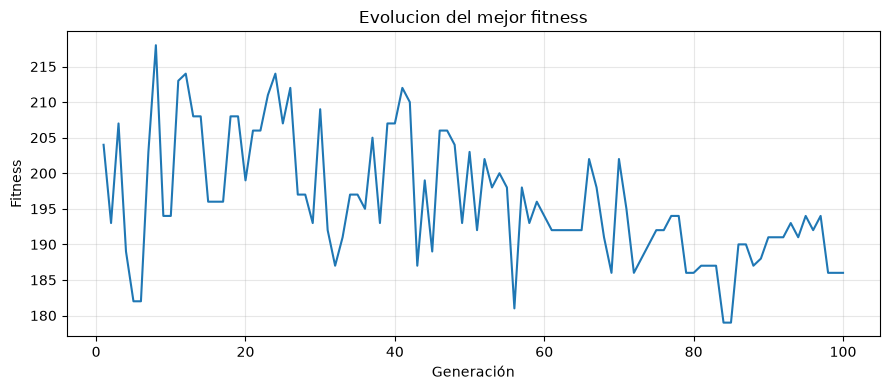

In [72]:
plt.figure(figsize=(9, 4))
plt.plot(historial["generación"], historial["fitness"])
plt.title("Evolucion del mejor fitness")
plt.xlabel("Generación")
plt.ylabel("Fitness")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()